# 05 — Incertitude: à quel point peut-on se fier à la prévision, et quand échoue-t-elle ?

Question 2 du manager. Le notebook 04 a établi que XGBoost **avec** la prévision RTE bat la barre (735 contre 845 MW). Une moyenne ne dit pas si on peut s'y fier un jour donné. Ici on mesure:

1. des **intervalles à 90 %**, et la couverture qu'ils livrent réellement;
2. **quand** le modèle échoue: température, charge, pics d'hiver, jours fériés, ponts, changements d'heure;
3. sa **robustesse** si la météo n'est pas parfaite (toute l'étude jusqu'ici suppose une prévision de température exacte);
4. ce que change un **coût asymétrique** de l'erreur.

Le modèle analysé est `with_rte`, refit tous les 90 jours (notebook 04). Les résultats viennent de `scripts/run_uncertainty.py`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from time_series_m2.baselines.naive import rte_debiased
from time_series_m2.uncertainty import pinball, rolling_conformal
from time_series_m2.uncertainty.failures import conditions, slice_table
from time_series_m2.utils.data import load_national
from time_series_m2.utils.metrics import by_hour, by_month, interval_coverage
from time_series_m2.utils.splits import mask

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 4)


def read(path):
    out = pd.read_csv(path, index_col=0)
    out.index = pd.to_datetime(out.index, utc=True).tz_convert('Europe/Paris')
    return out


df = load_national()
load = df['load_mw']
test_idx = df.index[mask(df.index, 'test')]

model = read('../results/xgboost/test_forecasts.csv')['with_rte_walk_forward']
bar = rte_debiased(df)
val_model = read('../results/uncertainty/val_forecasts.csv')['with_rte']

# one set of hours for every comparison: where the bar and the model both exist
common = test_idx[bar.reindex(test_idx).notna() & model.reindex(test_idx).notna()]
actual, model, bar = load[common], model[common], bar[common]
print(f'{len(common)} heures de test')

13102 heures de test


## 1. Intervalles de prédiction à 90 %

Deux constructions, comparées sur ce qu'elles livrent et non sur ce qu'elles annoncent:

- **Quantiles XGBoost**: deux boosters entraînés avec la perte quantile (5 % et 95 %), refit tous les 90 jours.
- **Conformelle glissante**: au point de prévision on ajoute les quantiles empiriques des **erreurs récentes** du modèle, par heure du jour, sur les 60 derniers jours **réalisés au moment de l'enchère** (jusqu'à J-2). Aucune hypothèse de loi, et la bande s'élargit dès que les erreurs grossissent. Elle est amorcée par les prévisions hors échantillon de 2024.

In [2]:
conformal = rolling_conformal(load, pd.concat([val_model, read('../results/xgboost/test_forecasts.csv')['with_rte_walk_forward']]))
conformal = conformal.reindex(common)
quantile = read('../results/uncertainty/quantile_bands.csv').reindex(common)

bands = {'conformelle glissante': conformal, 'quantiles XGBoost': quantile}
pd.DataFrame({name: interval_coverage(actual, b['lower'], b['upper']) for name, b in bands.items()}).T.round(3)

,coverage,nominal,mean_width,hours
conformelle glissante,0.902,0.9,3207.515,13102.0
quantiles XGBoost,0.797,0.9,2572.893,13102.0


Une bande à 90 % qui ne couvre que 80 % des réalisations n'est pas une bande à 90 %. Les quantiles XGBoost sont plus étroits et trop optimistes. Une explication plausible, que je n'ai pas testée: ils sont ajustés sur l'historique 2019-2024, alors que la conformelle est calibrée sur les erreurs *récentes* et s'adapte quand les erreurs changent.

On retient donc la conformelle. Voyons si sa couverture tient partout, et pas seulement en moyenne.

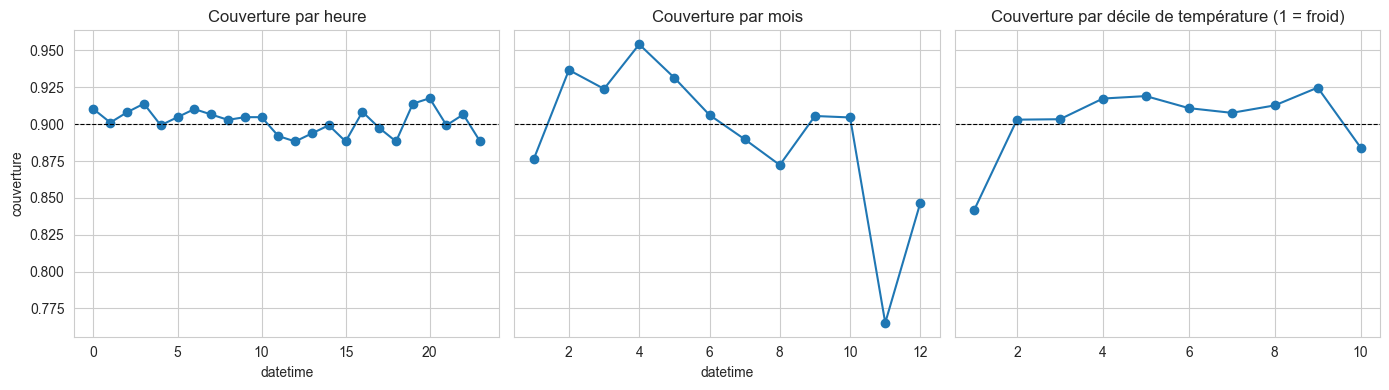

In [3]:
def coverage_by(index_key, band):
    inside = (actual >= band['lower']) & (actual <= band['upper'])
    return inside.groupby(index_key).mean()

cond = conditions(df).reindex(common)
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
coverage_by(common.hour, conformal).plot(ax=axes[0], marker='o', title='Couverture par heure')
coverage_by(common.month, conformal).plot(ax=axes[1], marker='o', title='Couverture par mois')
coverage_by(cond['temp_decile'].to_numpy(), conformal).plot(ax=axes[2], marker='o', title='Couverture par décile de température (1 = froid)')
for ax in axes:
    ax.axhline(0.9, color='k', lw=0.8, ls='--')
axes[0].set_ylabel('couverture')
plt.tight_layout()

In [4]:
peak = cond['winter_peak'].to_numpy()
rows = {
    'toutes les heures': interval_coverage(actual, conformal['lower'], conformal['upper']),
    'pics du soir d\'hiver (18-21 h, DJF)': interval_coverage(actual[peak], conformal['lower'][peak], conformal['upper'][peak]),
    'jours fériés': interval_coverage(actual[cond['holiday']], conformal['lower'][cond['holiday']], conformal['upper'][cond['holiday']]),
    'ponts': interval_coverage(actual[cond['bridge_day']], conformal['lower'][cond['bridge_day']], conformal['upper'][cond['bridge_day']]),
    'changement d\'heure': interval_coverage(actual[cond['dst_change_day']], conformal['lower'][cond['dst_change_day']], conformal['upper'][cond['dst_change_day']]),
}
pd.DataFrame(rows).T.round(3)

,coverage,nominal,mean_width,hours
toutes les heures,0.902,0.9,3207.515,13102.0
"pics du soir d'hiver (18-21 h, DJF)",0.903,0.9,4486.567,596.0
jours fériés,0.735,0.9,2992.892,408.0
ponts,0.792,0.9,3189.295,168.0
changement d'heure,0.800,0.9,3022.786,70.0


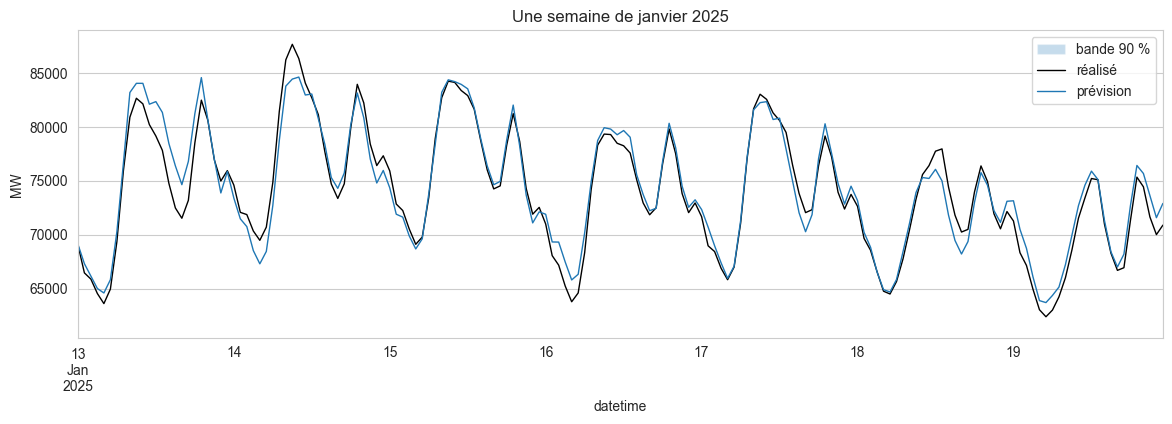

In [5]:
week = slice('2025-01-13', '2025-01-19')
fig, ax = plt.subplots(figsize=(14, 4))
ax.fill_between(conformal.loc[week].index, conformal['lower'].loc[week], conformal['upper'].loc[week],
                alpha=0.25, label='bande 90 %')
actual.loc[week].plot(ax=ax, color='k', lw=1, label='réalisé')
model.loc[week].plot(ax=ax, color='C0', lw=1, label='prévision')
ax.set(title='Une semaine de janvier 2025', ylabel='MW')
ax.legend()

## 2. Quand le modèle échoue

Le modèle est comparé à la barre **dans chaque condition**: ce qui compte n'est pas où il se trompe, mais où il se trompe *plus que RTE débiaisé*.

In [6]:
def table(by):
    t = slice_table(actual, {'model': model, 'bar': bar}, by)
    t['gain_%'] = (t['MAE_bar'] - t['MAE_model']) / t['MAE_bar'] * 100
    return t[['hours', 'MAE_model', 'MAE_bar', 'gain_%', 'bias_model']].round(1)

print('— par décile de température (1 = les heures les plus froides de l\'historique)')
display(table(cond['temp_decile']))
print('— par décile de charge')
display(table(cond['load_decile']))

— par décile de température (1 = les heures les plus froides de l'historique)


,hours,MAE_model,MAE_bar,gain_%,bias_model
1,1313.0,1042.7,1200.9,13.2,293.3
2,1238.0,832.4,961.8,13.5,20.9
3,1366.0,839.1,910.7,7.9,-42.8
4,1368.0,726.4,823.3,11.8,-22.4
5,1322.0,717.5,799.6,10.3,-9.7
6,1313.0,661.4,774.6,14.6,128.5
7,1300.0,652.3,767.2,15.0,149.6
8,1192.0,593.5,685.7,13.5,136.4
9,1197.0,580.9,654.5,11.3,182.2
10,1493.0,684.6,842.6,18.7,292.6


— par décile de charge


,hours,MAE_model,MAE_bar,gain_%,bias_model
1,1266.0,457.3,650.4,29.7,9.1
2,1257.0,565.6,693.4,18.4,29.5
3,1291.0,607.8,760.8,20.1,53.9
4,1441.0,626.9,729.6,14.1,117.8
5,1334.0,627.9,710.0,11.6,134.6
6,1316.0,698.2,792.7,11.9,202.3
7,1318.0,819.1,854.4,4.1,131.3
8,1348.0,913.3,958.7,4.7,89.7
9,1341.0,995.7,1123.1,11.3,163.3
10,1190.0,1049.4,1197.0,12.3,204.1


In [7]:
def where_true(flag):
    t = table(flag.astype(bool))
    return t[t.index.astype(bool)].iloc[0]


ordinary = ~(cond['holiday'] | cond['bridge_day'] | cond['dst_change_day'])
special = pd.DataFrame({
    'jour ordinaire': where_true(ordinary),
    'jour férié': where_true(cond['holiday']),
    'pont': where_true(cond['bridge_day']),
    'changement d\'heure': where_true(cond['dst_change_day']),
    'pic du soir d\'hiver': where_true(cond['winter_peak']),
    'week-end': where_true(cond['weekend']),
}).T
special

,hours,MAE_model,MAE_bar,gain_%,bias_model
jour ordinaire,12456.0,722.3,826.1,12.6,115.5
jour férié,408.0,1020.2,1268.6,19.6,170.5
pont,168.0,888.7,1209.9,26.6,-18.1
changement d'heure,70.0,954.0,808.9,-17.9,-212.2
pic du soir d'hiver,596.0,1065.1,1173.8,9.3,138.3
week-end,3742.0,770.4,909.8,15.3,159.9


In [8]:
daily = pd.DataFrame({
    'MAE_model': (actual - model).abs().groupby(common.normalize()).mean(),
    'MAE_bar': (actual - bar).abs().groupby(common.normalize()).mean(),
    'temp_moy_C': df['temperature_c'].reindex(common).groupby(common.normalize()).mean(),
})
daily['jour'] = daily.index.day_name()
daily.sort_values('MAE_model', ascending=False).head(10).round(0)

,MAE_model,MAE_bar,temp_moy_C,jour
datetime,,,,
2025-11-29 00:00:00+01:00,2404.0,1859.0,9.0,Saturday
2025-01-25 00:00:00+01:00,2351.0,1855.0,10.0,Saturday
2025-12-27 00:00:00+01:00,2267.0,2129.0,2.0,Saturday
2025-12-25 00:00:00+01:00,2231.0,1602.0,1.0,Thursday
2025-01-02 00:00:00+01:00,2078.0,3355.0,5.0,Thursday
2025-12-01 00:00:00+01:00,2048.0,2232.0,5.0,Monday
2025-01-06 00:00:00+01:00,2009.0,2866.0,10.0,Monday
2025-11-24 00:00:00+01:00,1946.0,2578.0,8.0,Monday
2025-11-01 00:00:00+01:00,1894.0,2787.0,15.0,Saturday


## 3. Robustesse à la météo

Toutes les features de température lisent la valeur **à l'heure cible**: c'est une prévision météo parfaite. Un desk réel n'a qu'une prévision. `perturb_temperature` ajoute à chaque jour une erreur gaussienne **constante sur la journée** (les erreurs de prévision météo persistent, elles ne sautent pas d'une heure à l'autre), d'écart type σ = 1 °C puis 2 °C, 5 tirages chacun.

Le modèle est entraîné sur les températures réelles (l'historique est observé), et seulement évalué sur les températures bruitées.

In [9]:
weather = pd.read_csv('../results/uncertainty/weather_robustness.csv')
bar_mae = (actual - bar).abs().mean()
agg = weather.groupby(['feature_set', 'sigma_c']).agg(
    MAE=('MAE', 'mean'), MAE_std=('MAE', 'std'), peak_MAE=('peak_MAE', 'mean'), bias=('bias', 'mean')
)
clean = agg.xs(0.0, level='sigma_c')['MAE']
agg['dégradation_%'] = [(r.MAE / clean[i[0]] - 1) * 100 for i, r in agg.iterrows()]
agg['vs_barre_%'] = (bar_mae - agg['MAE']) / bar_mae * 100
print(f'barre (RTE débiaisé): MAE = {bar_mae:.1f} MW')
agg.round(1)

barre (RTE débiaisé): MAE = 844.8 MW


MAE  MAE_std  peak_MAE   bias  dégradation_%  \
feature_set sigma_c                                                    
independent 0.0       960.0      NaN    1384.4  -99.4            0.0   
            1.0      1047.4     18.0    1608.7 -102.1            9.1   
            2.0      1265.2     29.6    2141.4  -94.7           31.8   
with_rte    0.0       734.9      NaN    1065.1  113.7            0.0   
            1.0       744.9      7.6    1097.9  104.4            1.4   
            2.0       778.2      9.6    1192.3  105.3            5.9   

                     vs_barre_%  
feature_set sigma_c              
independent 0.0           -13.6  
            1.0           -24.0  
            2.0           -49.8  
with_rte    0.0            13.0  
            1.0            11.8  
            2.0             7.9

## 4. Un coût asymétrique

Les données ne contiennent aucun prix de déséquilibre: aucun montant en euros n'est annoncé. Mais l'énoncé dit que les erreurs sont réglées à des prix de déséquilibre et que les pics du soir des jours froids sont les plus chers. Si un déficit (réalisé > prévu) coûte plus cher qu'un excédent, la bonne perte est la **perte pinball** au niveau τ = coût du déficit / (déficit + excédent). τ = 0,5 est la moitié de la MAE; τ = 0,7 signifie qu'un déficit coûte 2,3 fois un excédent.

In [10]:
rows = {}
for tau in (0.5, 0.6, 0.7, 0.8):
    for label, sel in (('toutes heures', slice(None)), ('pics du soir d\'hiver', peak)):
        b, m = pinball(actual[sel], bar[sel], tau), pinball(actual[sel], model[sel], tau)
        rows[(f'τ = {tau}', label)] = {'barre': b, 'modèle': m, 'gain_%': (b - m) / b * 100}
pd.DataFrame(rows).T.round(1)

barre  modèle  gain_%
τ = 0.5 toutes heures         422.4   367.5    13.0
        pics du soir d'hiver  586.9   532.6     9.3
τ = 0.6 toutes heures         421.4   378.8    10.1
        pics du soir d'hiver  579.4   546.4     5.7
τ = 0.7 toutes heures         420.4   390.2     7.2
        pics du soir d'hiver  572.0   560.2     2.1
τ = 0.8 toutes heures         419.3   401.6     4.2
        pics du soir d'hiver  564.5   574.1    -1.7

## 5. Conclusion

**Réponse à la question 2: quelle incertitude, et quand ça échoue.**

**Les intervalles.** La bande conformelle glissante tient sa promesse: **90,2 % de couverture** sur 13 102 heures de test, pour une largeur moyenne de 3207 MW. Les quantiles XGBoost n'en livrent que **79,7 %**: ils sont trop étroits, et il ne faut pas les utiliser tels quels. La couverture de la conformelle est de 90,3 % sur les pics du soir d'hiver, mais la bande y est plus large (4487 MW): c'est précisément là que l'incertitude est la plus grande. Elle sous-couvre en revanche les jours atypiques: **73,5 % sur les jours fériés** (408 h), **79,2 % sur les ponts** (168 h) et **80 % les jours de changement d'heure** (70 h, trois jours seulement, à lire avec prudence). Ces jours sont rares dans la fenêtre de calibration de 60 jours, donc la bande ne les anticipe pas.

**Où le modèle échoue.**

- Il bat la barre dans **chaque décile de température** (de +8 % à +19 %) et de charge (de +4 % à +30 %). Le gain est le plus faible dans les déciles 7 et 8 de charge (+4 %).
- Son biais n'est pas nul aux extrêmes: **+293 MW dans le décile le plus froid et dans le plus chaud**, c'est-à-dire qu'il sous-prévoit la demande quand il fait très froid ou très chaud.
- Les jours fériés (1020 MW de MAE) et les ponts (889 MW) sont plus difficiles que les jours ordinaires (722 MW), même si le modèle y reste meilleur que la barre.
- **Les jours de changement d'heure, le modèle fait moins bien que la barre** (954 contre 809 MW), sur seulement 70 heures: trois jours, pas de quoi conclure à une faiblesse structurelle, mais un cas à surveiller.
- Les dix pires jours sont surtout des week-ends et des jours fériés ou voisins (29 novembre, 25 janvier, 25 et 27 décembre, 1er novembre); le modèle fait mieux que la barre sur cinq d'entre eux et moins bien sur les cinq autres. Je n'ai pas identifié la cause des erreurs des samedis 29 novembre et 25 janvier.

**Robustesse à la météo.** Les écarts types de 1 °C et 2 °C sont des hypothèses, pas des erreurs de prévision mesurées.

- Avec RTE comme entrée, le modèle encaisse bien: MAE de 735 à **745 MW** (σ = 1 °C, +1,4 %) puis **778 MW** (σ = 2 °C, +5,9 %), donc toujours meilleur que la barre de 845 MW, de 8 % au pire. **Sur les pics d'hiver, en revanche, il passe à 1192 MW à σ = 2 °C, au-dessus des 1174 MW de la barre.**
- Sans RTE, il est très sensible: +9 % (σ = 1 °C) et **+32 %** (σ = 2 °C, 1265 MW). Sans la prévision RTE, la qualité du modèle dépend de celle de la météo.

**Coût asymétrique.** Aucun prix de déséquilibre n'est disponible, donc pas de montant en euros. Le gain contre la barre fond à mesure qu'un déficit coûte plus cher qu'un excédent: de 13 % (τ = 0,5) à 7 % (τ = 0,7) sur toutes les heures, et **sur les pics d'hiver de 9 % à 2 % puis à −1,7 % à τ = 0,8: la barre y devient meilleure**. La cause probable est le biais positif du modèle (+138 MW sur les pics, il sous-prévoit); la corriger par un biais glissant est une piste, non testée ici.

**Ce que ça implique pour la décision (question 3).**

- Déployer avec les **bandes conformelles**, pas les quantiles.
- Ne pas se fier à la bande les jours fériés, les ponts et les changements d'heure; prévoir une marge manuelle.
- Le gain du modèle sur les pics d'hiver, ceux qui coûtent le plus, est le plus fragile: il disparaît si la météo est mal prévue (σ = 2 °C) ou si le déficit est fortement pénalisé.
- Le modèle dépend de RTE, et d'une prévision météo raisonnable.